In [1]:
%%time
dataset_name = "W30_comb"
df_list = "BES_Panel"

%matplotlib inline 
%run BES_header.py {dataset_name} {df_list}

global BES_label_list, BES_df_list

Toggle code

var_type (12866, 13)
old_new_col_names not loaded
CPU times: total: 15.8 s
Wall time: 1min 9s


In [2]:
pan_dataset_values = pd.read_pickle(BES_small_data_files+"pan_dataset_allr_valuesW19.zip",compression='zip')

In [ ]:
# pie chart grid for vote flows by political compass position

In [ ]:
# 2024 Vote, values, 2025VI

In [164]:
BES_Panel["p_past_vote_2024"][BES_Panel["wt_new_W30"].notnull()].value_counts(dropna=False)

p_past_vote_2024
Labour                           9168
Conservative                     5544
NaN                              4312
Brexit Party/Reform UK           3787
Liberal Democrat                 3463
Green Party                      1883
Scottish National Party (SNP)     771
Other                             555
Don't know                        348
An independent candidate          261
Plaid Cymru                       250
Name: count, dtype: int64

In [163]:
# search(BES_Panel,"p_past_vote|generalElectionVoteW30|wt_new_W30")
BES_Pie["past_vote"].value_counts()

past_vote
Labour                           6332
Conservative                     4585
Brexit Party/Reform UK           2973
Liberal Democrat                 2518
DNV                              2208
Green Party                      1093
Scottish National Party (SNP)     580
Other                             401
Don't know                        210
An independent candidate          199
Plaid Cymru                       186
Name: count, dtype: int64

In [ ]:
# p_past_vote_2024, generalElectionVoteW30, wt_new_W30

In [246]:
BES_Pie = BES_Panel[["p_past_vote_2024","generalElectionVoteW30","wt_new_W30","countryW30"]].copy()
BES_Pie.columns = ["past_vote","VI","wt","country"]
BES_Pie["past_vote"] = BES_Pie["past_vote"].astype('object')
BES_Pie.loc[BES_Panel["p_turnout_2024"]=='No, I did not vote',"past_vote"] = "DNV"


index_overlap = list(set(pan_dataset_values.index).intersection(set(BES_Pie.index)))

# al_lr_cols = ["Economic: Left <-> Right{gaussian-ish}complete_fully","Social: Liberalism <-> Conservatism{gaussian-ish}complete_fully"]
# BES_Pie[al_lr_cols]=np.nan
# BES_Pie.loc[index_overlap,al_lr_cols]=pan_dataset_values.loc[index_overlap,al_lr_cols]

BES_Pie = BES_Pie.dropna()

replace_dict = {'Labour':"LAB", "Don't know":"DK+", 'Liberal Democrat':"LD",
                  'Brexit Party/Reform UK':"REFUK", 'Green Party':"GP", 'Conservative':"CON",
                  'I would/did not vote':"DK+", 'Other':"DK+",
                  'Scottish National Party (SNP)':np.nan, 'Plaid Cymru':np.nan}
rev_replace_dict = {"LAB":"Labour","LD":"Liberal Democrat","REFUK":"Brexit Party/Reform UK","GP":"Green Party","CON":"Conservative"}
BES_Pie["SimpleVote"] = BES_Pie["VI"].astype('object').replace(replace_dict)
# BES_Pie["SimpleVote"][mask].value_counts()
BES_Pie["SimpleVote"] = BES_Pie["SimpleVote"].astype('category').cat.reorder_categories(['CON', 'DK+', 'GP','LD',  'LAB', 'REFUK'])

In [87]:
VoteBase = (BES_Pie["past_vote"]=="Labour")
CountryMask = (BES_Pie["country"]=="England")
mask =  VoteBase& CountryMask

BES_Pie[mask]["VI"].value_counts()

VI
Labour                           2565
Don't know                       1031
Liberal Democrat                  543
Brexit Party/Reform UK            418
Green Party                       395
Conservative                       95
I would/did not vote               83
Other                              67
Scottish National Party (SNP)       0
Plaid Cymru                         0
Name: count, dtype: int64

In [ ]:
## simplification DK/WNV/OTH - merged?

In [178]:
item_list

['al_scaleW1_W5',
 'al_scaleW6',
 'al_scaleW7_W9',
 'al_scaleW10_W12',
 'al_scaleW13',
 'al_scaleW14W15',
 'al_scaleW16',
 'al_scaleW17_W19',
 'al_scaleW20',
 'al_scaleW21',
 'al_scaleW22',
 'al_scaleW23',
 'al_scaleW24',
 'al_scaleW25W26',
 'al_scaleW27W29',
 'al_scaleW30']

In [182]:
list(range(1,4))

[1, 2, 3]

0.943330729850473


count    4068.000000
mean       13.118142
std         4.475686
min         0.018477
25%        10.283530
50%        13.964576
75%        16.513683
max        20.099114
Name: al_scaleW30, dtype: float64

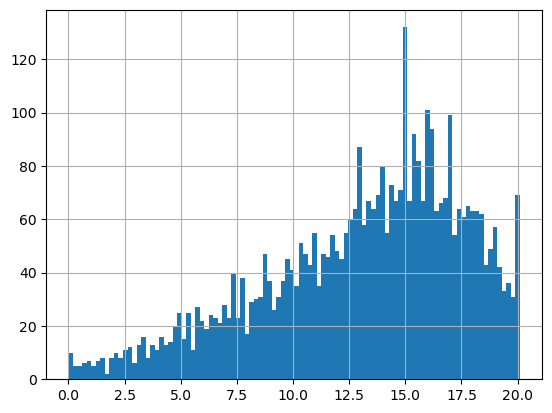

In [235]:
BES_als = BES_Panel[ search(BES_Panel,"al_scale").index ].apply(lambda x: x.cat.codes).replace(-1,np.nan)
BES_als["al_scaleW30"]=BES_als["al_scaleW30"] + ((-BES_als["al_scaleW30"]+BES_als["al_scaleW27W29"])/2) \
    + ((-BES_als["al_scaleW30"]+BES_als["al_scaleW25W26"])/4) \
    + ((-BES_als["al_scaleW30"]+BES_als["al_scaleW24"])/8)
    # + (-BES_als["al_scaleW30"]+BES_als["al_scaleW23"])/16 


BES_als["al_scaleW30"] = BES_als["al_scaleW30"] + np.random.rand(BES_als["al_scaleW30"].shape[0])*.1
print(BES_als["al_scaleW30"].corr(BES_Panel["al_scaleW30"].cat.codes.replace(-1,np.nan)))
BES_als["al_scaleW30"].hist(bins=100)
pd.qcut(BES_als["al_scaleW30"],q=200,duplicates='drop').value_counts()
BES_als["al_scaleW30"].describe()

In [239]:
item_list[position].split(scale)[1]

'W30'

In [238]:
scale.split("_")[0]+"_raw"

'lr_raw'

0.9741008730165807


(al_rawW30
 (-0.001, 0.587]     133
 (13.954, 13.965]    133
 (13.992, 14.005]    133
 (14.005, 14.018]    133
 (14.053, 14.207]    133
                    ... 
 (14.961, 14.972]    132
 (9.276, 9.479]      132
 (14.767, 14.927]    132
 (14.513, 14.642]    132
 (15.457, 15.485]    132
 Name: count, Length: 200, dtype: int64,
 count    26542.000000
 mean        12.409458
 std          4.515323
 min          0.000000
 25%          9.275877
 50%         13.008845
 75%         15.953054
 max         20.000000
 Name: al_rawW30, dtype: float64)

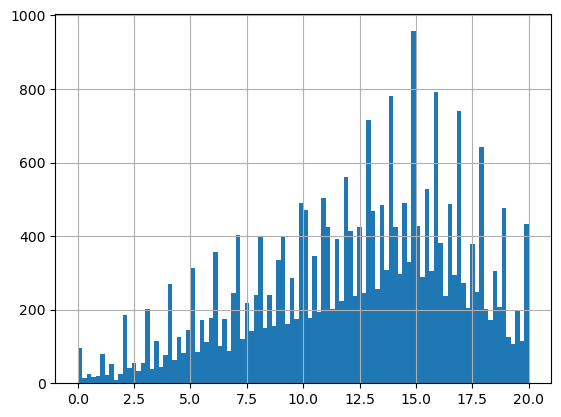

In [276]:
BES_als = BES_Panel[ search(BES_Panel,"al_scale|lr_scale").index ].apply(lambda x: x.cat.codes).replace(-1,np.nan)

for scale in ["lr_scale","al_scale"]:
    item_list = list(search(BES_als,scale).index)
    for position in [15]:
    #range(0,len(item_list)):
        new_var_name = scale.split("_")[0]+"_raw"+item_list[position].split(scale)[1]
        
        BES_als[new_var_name] = BES_als[item_list[position]].fillna(5)
        
        for seq in range(1,4):
            seq_pos = position-seq
            if seq_pos<0:
                seq_pos = position-seq_pos
            BES_als[new_var_name] = BES_als[new_var_name]+((BES_als[item_list[seq_pos]]-BES_als[item_list[position]])/(2**seq)).fillna(0)
            
        BES_als[new_var_name] = BES_als[new_var_name] + np.random.rand(BES_als[new_var_name].shape[0])*.1
        # correct to range 0-20
        BES_als[new_var_name]=BES_als[new_var_name]-BES_als[new_var_name].min()
        BES_als[new_var_name]=BES_als[new_var_name]*20/BES_als[new_var_name].max()

mask = BES_Panel["al_scaleW30"].notnull()

print(BES_als["al_rawW30"][mask].corr(BES_Panel["al_scaleW30"][mask].cat.codes.replace(-1,np.nan)))
BES_als["al_rawW30"][mask].hist(bins=100)
pd.qcut(BES_als["al_rawW30"][mask],q=200,duplicates='drop').value_counts(),BES_als["al_rawW30"][mask].describe()

In [261]:
BES_als["al_rawW30"].notnull().sum()

4068

In [10]:
# choices - make the political compass specific to Labour vote/England?


In [81]:
# BES_Pie["Economic Left-Right"].isnull().sum()

In [82]:
# BES_Pie.groupby( ["Economic Left-Right","Social Lib-Auth"] )\
#     .apply(lambda x: weighted_value_counts(x["SimpleVote"],x["wt_new_W30"],normalize=True,percent=True))\
#     .loc[0.0,0.0]

In [152]:
BES_Panel["p_turnout_2024"]

id
1                        NaN
2                        NaN
3                        NaN
4                        NaN
5                        NaN
                 ...        
123795    No, I did not vote
123796          Yes, I voted
123797          Yes, I voted
123798    No, I did not vote
123799          Yes, I voted
Name: p_turnout_2024, Length: 122372, dtype: category
Categories (3, object): ['No, I did not vote' < 'Yes, I voted' < 'Don't know']

In [243]:
BES_Pie,BES_als

(                           past_vote                             VI        wt  \
 id                                                                              
 18     Scottish National Party (SNP)  Scottish National Party (SNP)  0.453541   
 24                            Labour                    Green Party  1.136879   
 30                       Green Party                    Green Party  0.477598   
 31                               DNV         Brexit Party/Reform UK  0.888236   
 33                            Labour                         Labour  0.342641   
 ...                              ...                            ...       ...   
 98390         Brexit Party/Reform UK         Brexit Party/Reform UK  0.543002   
 98393                            DNV           I would/did not vote  1.498417   
 98395                            DNV                         Labour  2.000320   
 98433         Brexit Party/Reform UK         Brexit Party/Reform UK  0.965875   
 98449          

In [150]:
BES_Panel["p_past_vote_2024"].value_counts(dropna=False)

p_past_vote_2024
NaN                              86945
Labour                           12725
Conservative                      7182
Brexit Party/Reform UK            5090
Liberal Democrat                  4726
Green Party                       2681
Scottish National Party (SNP)     1026
Other                              742
Don't know                         509
An independent candidate           414
Plaid Cymru                        332
Name: count, dtype: int64

In [85]:
# temp = BES_Pie.groupby( ["Economic Left-Right","Social Lib-Auth"] )\
#     .apply(lambda x: weighted_value_counts(x["SimpleVote"],x["wt_new_W30"],normalize=True,percent=True))\
#     .loc[0.0,0.0]["weighted_sample_fraction"].sort_index()
# plt.pie( temp,colors = [palette_dict[x] for x in temp.index]);

In [277]:
def pie(SimpleVote, weights,color=None):
    global party_weight    
    global party_scale
    temp = weighted_value_counts(SimpleVote,weights,normalize=True,percent=True).sort_index()
    plt.pie( temp["weighted_sample_fraction"],colors = [palette_dict[x] for x in temp.index],
            radius=party_scale*weights.sum()/(party_weight/q**2),startangle=90,counterclock=False);

def pol_com_pie_chart( party , country="England", q=5, scale=.5  ):

    if party=="ALL":
        VoteBase = BES_Pie["past_vote"].notnull()
    else:
        VoteBase = (BES_Pie["past_vote"]==rev_replace_dict[party])
    CountryMask = (BES_Pie["country"]==country)
    mask =  VoteBase& CountryMask
    # print(BES_Pie["past_vote"][mask].value_counts())
    global party_weight
    global party_scale      
    party_scale=scale
  
    party_weight = BES_Pie[mask]["wt"].sum()

    # BES_Pie["Economic Left-Right"] = weighted_qcut(BES_Pie[al_lr_cols[0]][CountryMask],BES_Pie["wt"][CountryMask],q=q).cat.codes
    # BES_Pie["Economic Left-Right"] = BES_Pie["Economic Left-Right"].fillna(-1).astype(int)
    
    # BES_Pie["Social Lib-Auth"]     = weighted_qcut(BES_Pie[al_lr_cols[1]][CountryMask],BES_Pie["wt"][CountryMask],q=q).cat.codes
    # BES_Pie["Social Lib-Auth"] = BES_Pie["Social Lib-Auth"].fillna(-1).astype(int)

    BES_Pie["Economic Left-Right"] = weighted_qcut(BES_als.loc[BES_Pie.index,"lr_rawW30"][CountryMask],BES_Pie["wt"][CountryMask],q=q).cat.codes
    BES_Pie["Economic Left-Right"] = BES_Pie["Economic Left-Right"].fillna(-1).astype(int)
    
    BES_Pie["Social Lib-Auth"]     = weighted_qcut(BES_als.loc[BES_Pie.index,"al_rawW30"][CountryMask],BES_Pie["wt"][CountryMask],q=q).cat.codes
    BES_Pie["Social Lib-Auth"] = BES_Pie["Social Lib-Auth"].fillna(-1).astype(int)
    
    palette_dict = { "CON":"blue","REFUK":"cyan","LD":"orange","DK+":"gray","LAB":"red","GP":"green" }
    

    
    g = sns.FacetGrid(BES_Pie[mask], row="Social Lib-Auth",col="Economic Left-Right",
                      margin_titles=True,height=1,aspect=1,row_order = [4,3,2,1,0])
    g.map(pie,"SimpleVote","wt");
    g.figure.subplots_adjust(wspace=0, hspace=0);
    g.set_xlabels("");
    g.set_ylabels("");
    g.set_titles(row_template='{row_name}',col_template='{col_name}');
    g.tight_layout();
    plt.text(-10,14.5,"Economic: Left(0) - Right(4)",fontsize=16);
    plt.text(2.5,2,"Social: Auth(4) - Lib(0)",rotation=270,fontsize=16);
    plt.text(-14,16,"("+country+") "+party+" 2024GE -> May 2025 VI",fontsize=20);

In [258]:
BES_als.loc[BES_Pie.index,"lr_rawW30"][BES_Pie["country"]=="England"].notnull().sum()

3675

,past_vote,VI,wt,country,SimpleVote
id,,,,,
18,Scottish National Party (SNP),Scottish National Party (SNP),0.453541,Scotland,NaN
24,Labour,Green Party,1.136879,England,GP
30,Green Party,Green Party,0.477598,England,GP
31,DNV,Brexit Party/Reform UK,0.888236,Wales,REFUK
33,Labour,Labour,0.342641,England,LAB
...,...,...,...,...,...
123795,DNV,Don't know,7.311021,England,DK+
123796,Liberal Democrat,Liberal Democrat,1.545915,England,LD
123797,Conservative,Conservative,1.816420,England,CON


CPU times: total: 2.38 s
Wall time: 2.48 s


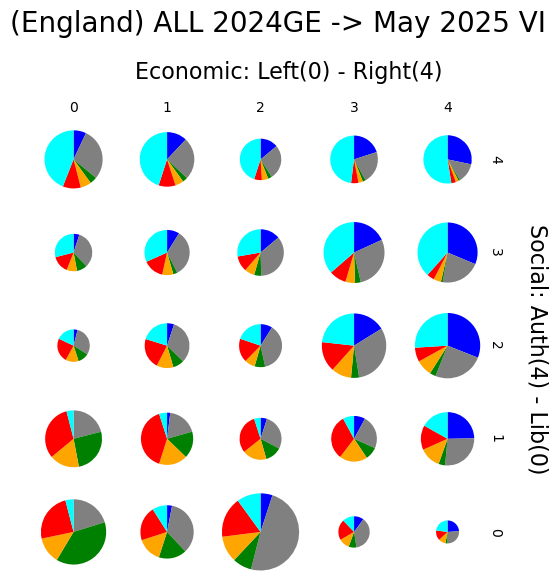

In [279]:
%%time
pol_com_pie_chart( "ALL",scale=.8 )

CPU times: total: 2.16 s
Wall time: 2.25 s


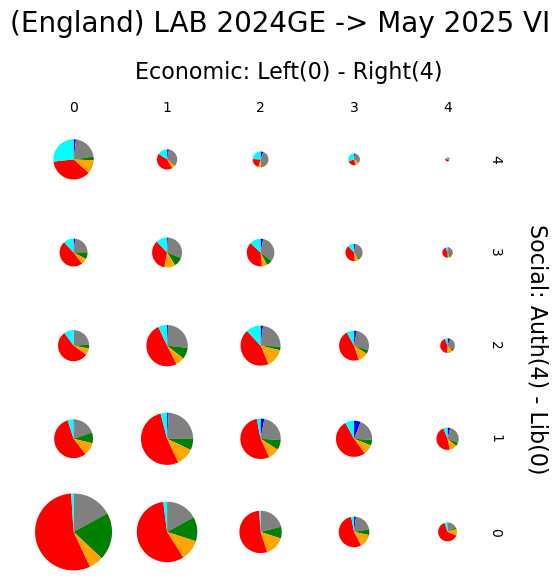

In [131]:
%%time
pol_com_pie_chart( "LAB" )

CPU times: total: 2.09 s
Wall time: 2.25 s


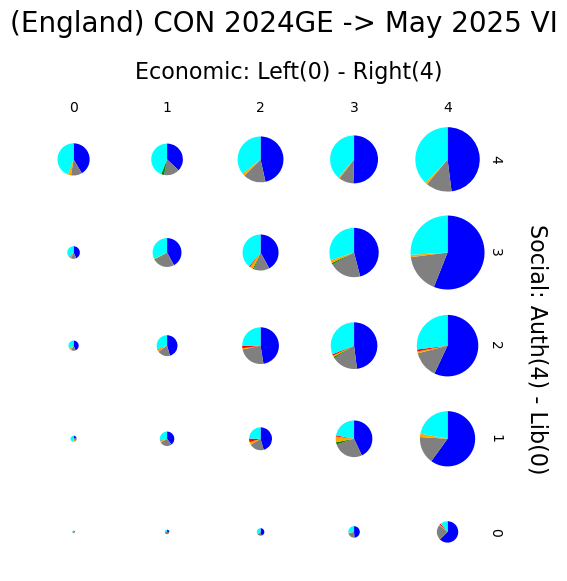

In [132]:
%%time
pol_com_pie_chart( "CON" )

CPU times: total: 1.56 s
Wall time: 1.68 s


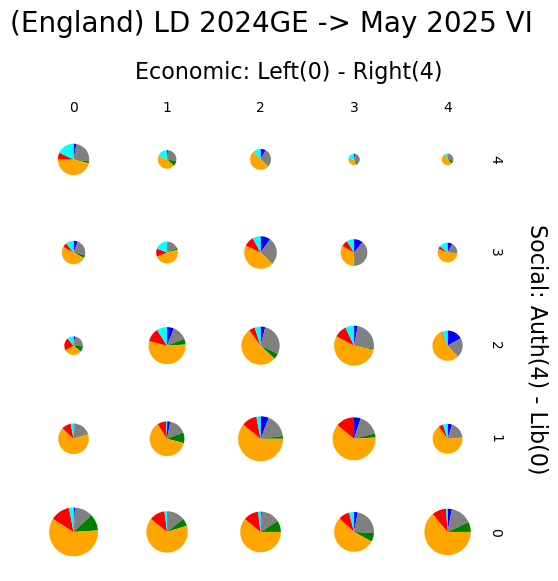

In [133]:
%%time
pol_com_pie_chart( "LD" )

CPU times: total: 2.05 s
Wall time: 2.2 s


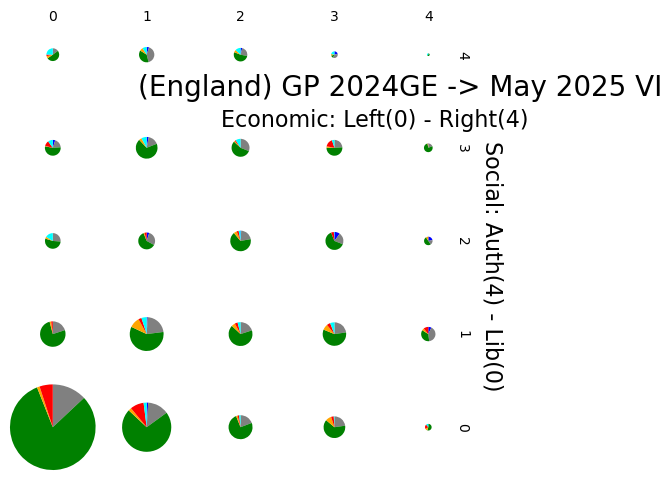

In [136]:
%%time
pol_com_pie_chart( "GP"),scale=.3 )

CPU times: total: 2.45 s
Wall time: 2.63 s


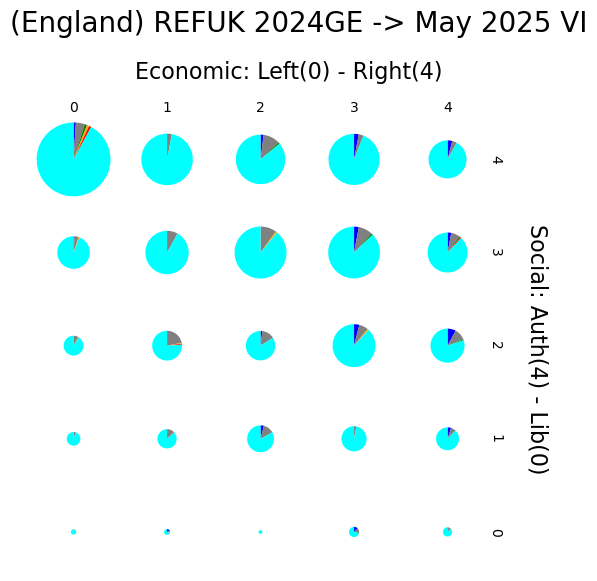

In [135]:
%%time
pol_com_pie_chart( "REFUK" )

CPU times: total: 2.61 s
Wall time: 2.86 s


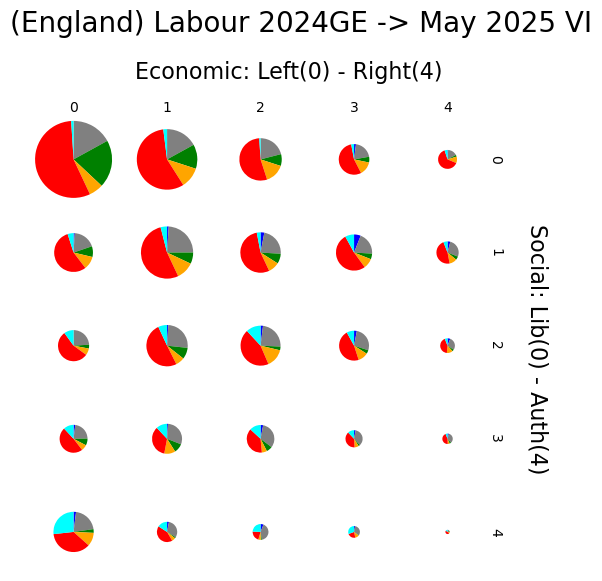

In [80]:
%%time
q=5

BES_Pie["Economic Left-Right"] = pd.qcut(BES_Pie[al_lr_cols[0]][CountryMask],q=q).cat.codes
BES_Pie["Economic Left-Right"] = BES_Pie["Economic Left-Right"].fillna(-1).astype(int)

BES_Pie["Social Lib-Auth"]     = pd.qcut(BES_Pie[al_lr_cols[1]][CountryMask],q=q).cat.codes
BES_Pie["Social Lib-Auth"] = BES_Pie["Social Lib-Auth"].fillna(-1).astype(int)

palette_dict = { "CON":"blue","REFUK":"cyan","LD":"orange","DK+":"gray","LAB":"red","GP":"green" }

def pie(SimpleVote, weights,color=None):
    temp = weighted_value_counts(SimpleVote,weights,normalize=True,percent=True).sort_index()
    plt.pie( temp["weighted_sample_fraction"],colors = [palette_dict[x] for x in temp.index],
            radius=.5*weights.sum()/(BES_Pie[mask]["wt"].sum()/q**2),startangle=90,counterclock=False);

g = sns.FacetGrid(BES_Pie[mask], row="Social Lib-Auth",col="Economic Left-Right",margin_titles=True,height=1,aspect=1)
g.map(pie,"SimpleVote","wt");
g.figure.subplots_adjust(wspace=0, hspace=0);
g.set_xlabels("");
g.set_ylabels("");
g.set_titles(row_template='{row_name}',col_template='{col_name}');
g.tight_layout();
plt.text(-10,14.5,"Economic: Left(0) - Right(4)",fontsize=16);
plt.text(2.5,2,"Social: Lib(0) - Auth(4)",rotation=270,fontsize=16);
plt.text(-14,16,"(England) Labour 2024GE -> May 2025 VI",fontsize=20);


In [43]:
BES_Pie["Social Lib-Auth"]

id
18       NaN
24       0.0
30       3.0
33       0.0
34       2.0
        ... 
98332    NaN
98346    2.0
98367    NaN
98390    0.0
98433    0.0
Name: Social Lib-Auth, Length: 19077, dtype: float64